In [115]:
import sys
from types import MethodType

sys.path.append(r"C:\Users\admin\Documents\GitHub\THA\lib")
from pathlib import Path
import argparse

import numpy as np
import torch
import torch.utils
import torch.utils.data
import wandb
import lightning.pytorch as pl
from lightning.pytorch.loggers.wandb import WandbLogger
from lightning.pytorch.callbacks import LearningRateMonitor

torch.set_default_dtype(torch.float64)

from nRTD.rtd_fitting import RTDModule, RTDDataModule
#from SweepRunner import Sweeper
import matplotlib.pyplot as plt

plt.style.use("ICIWstyle")

# 1 - data import

In [116]:
# npz datein von n_dot und t

path_data_capillary = r"C:\Users\admin\Documents\GitHub\THA\Experiments\THA_001\A_capillary_2barabs\nRTD_ptk_capillary_nocat_25°C_1bar_reactor125mlmin_matrix0mlmin.npz"
path_data_reactor_inlet = r"C:\Users\admin\Documents\GitHub\THA\Experiments\THA_001\B_vorreaktor_2barabs\nRTD_ptk_vorreaktor_nocat_25°C_1bar_reactor125mlmin_matrix0mlmin.npz"
path_data_reactor_outlet = r"C:\Users\admin\Documents\GitHub\THA\Experiments\THA_001\C_nachreaktor_2barabs\nRTD_ptk_nachreaktor_nocat_150°C_aequi_2bar_reactor250mlmin_matrix0mlmin.npz"
path_data_total_system = r"C:\Users\admin\Documents\GitHub\THA\Experiments\THA_001\D_gessys_2barabs\nRTD_ptk_gessys_nocat_150°C_aequi_2bar_reactor250mlmin_matrix0mlmin.npz"



# path_data_capillary = r"C:\Users\admin\Documents\GitHub\THA\Experiments\HSA_001\data\FBA-E-18032025_300ml-min_Analytik_MS.npz"
# path_data_reactor_inlet = r"C:\Users\admin\Documents\GitHub\THA\Experiments\HSA_002\data\MGA-E-11032025_30ml-min_1atm_ReactorInlet_MS.npz"
# path_data_reactor_outlet =r"C:\Users\admin\Documents\GitHub\THA\Experiments\HSA_003\data\MGA-E-11032025_30ml-min_1atm_ReactorOutlet_MS.npz"
# path_data_total_system = r"C:\Users\admin\Documents\GitHub\THA\Experiments\HSA_004\data\MGA-E-10032025_30ml-min_1atm_TotalSystem.npz"

# 2 - plotting

In [117]:
def log_plots(data_module: RTDDataModule, model: RTDModule, index=0, Es_to_plot=[0]):
    pred_y, pred_t = model(data_module.x, data_module.t_in)
    pred_t = pred_t.detach().numpy().squeeze()
    pred_y = pred_y.detach().numpy().squeeze()

    fig = plt.figure()
    index = 0
    plt.plot(
        data_module.t_in[index],
        data_module.x[index].squeeze(),
        ls="--",
    )
    plt.plot(
        data_module.t_in[index + 2],
        data_module.x[index + 2].squeeze(),
        ls="--",
    )
    plt.plot(
        data_module.t_out[index],
        data_module.y[index].squeeze(),
        "o",
        c="C0",
        markersize=0.5,
    )
    plt.plot(
        data_module.t_out[index + 2],
        data_module.y[index + 2].squeeze(),
        "o",
        c="C1",
        markersize=0.5,
    )
    plt.plot(
        data_module.t_in[index + 1],
        data_module.x[index + 1].squeeze(),
        ls="--",
        c="C2",
    )
    plt.plot(
        data_module.t_in[index + 3],
        data_module.x[index + 3].squeeze(),
        ls="--",
        c="C3",
    )
    plt.plot(
        data_module.t_out[index + 1],
        data_module.y[index + 1].squeeze(),
        "o",
        c="C2",
        markersize=0.5,
    )
    plt.plot(
        data_module.t_out[index + 3],
        data_module.y[index + 3].squeeze(),
        "o",
        c="C3",
        markersize=0.5,
    )

    plt.plot(pred_t[index, :], pred_y[index, :], c="C0")
    plt.plot(pred_t[index + 2].squeeze(), pred_y[index + 2].squeeze(), c="C1")
    plt.plot(pred_t[index + 1, :], pred_y[index + 1, :], c="C2")
    plt.plot(pred_t[index + 3].squeeze(), pred_y[index + 3].squeeze(), c="C3")
    plt.xlabel("t / s")
    plt.ylabel("x / 1")
    plt.twinx()
    ax = plt.gca()
    plt.ylabel("$E \;/\; s^{-1}$")
    my_colors = ["darkmagenta", "goldenrod", "firebrick", "darkcyan"]
    for E_index in Es_to_plot:
        ax.plot(
            model.net.conv_layers[E_index].t_kernel.detach().numpy(),
            model.net.E[E_index],
            color=my_colors[E_index],
        )
    wandb.log({f"RTD_Plot_img": wandb.Image(fig)})
    wandb.log({f"RTD_Plot_fig": fig})

<>:67: SyntaxWarning:

invalid escape sequence '\;'

<>:67: SyntaxWarning:

invalid escape sequence '\;'

C:\Users\admin\AppData\Local\Temp\ipykernel_16356\3345537236.py:67: SyntaxWarning:

invalid escape sequence '\;'



# 3 - constans

In [118]:
# givens
t_out = (0.0, 120.0)
n_out = int(4 * (t_out[1] - t_out[0]) + 1)
delta_t_out = (t_out[1] - t_out[0]) / (n_out - 1)

# the capillary times
# FBA_18032025_300ml-min_Analytik_MS
switching_periods = np.array(
    [
        120 + 0.09,
        120 - 0.09,
        120 - 0.08,
        120 + 0.02,
        120 - 0.03,
        120 - 0.01,
        120 - 0.01,
        120 - 0.11,
        120 - 0.05,
        120 + 0.07,
    ]
)

t_offset_capillary = 8716.144
t_offset_reactor_inlet = 9391
t_offset_reactor_outlet = 20685
t_offset_ges_system = 16019

# the piping times
t_halfperiod = t_out[1] - t_out[0]

# switching_times_cap = np.flip(np.cumsum(-switching_periods))
# switching_times_cap = (
#     np.append(switching_times_cap, 0) - 1
# )  # leave enough time for the step


# automated_switching_times = np.full((20,), t_halfperiod)
# switching_times_reac_inlet = np.insert(automated_switching_times, 0, 7.4 - 1.0)
# switching_times_reac_inlet = np.cumsum(switching_times_reac_inlet)
# switching_times_reac_outlet = np.insert(automated_switching_times, 0, 7.5 - 0.25 - 1.0)
# switching_times_reac_outlet = np.cumsum(switching_times_reac_outlet)
# switching_times_total_system = np.insert(automated_switching_times, 0, 7.5 - 0.5 - 1.0)
# switching_times_total_system = np.cumsum(switching_times_total_system)

automated_switching_times = np.full((20,), t_halfperiod)
switching_times_cap = np.insert(automated_switching_times, 0, t_offset_capillary)
switching_times_cap = np.cumsum(switching_times_cap)
switching_times_reac_inlet = np.insert(automated_switching_times, 0, t_offset_reactor_inlet)
switching_times_reac_inlet = np.cumsum(switching_times_reac_inlet)
switching_times_reac_outlet = np.insert(automated_switching_times, 0, t_offset_reactor_outlet)
switching_times_reac_outlet = np.cumsum(switching_times_reac_outlet)
switching_times_total_system = np.insert(automated_switching_times, 0, t_offset_ges_system)
switching_times_total_system = np.cumsum(switching_times_total_system)

# t_kernels = [
#     (0.0, 30.0),  # piping to reactor inlet
#     (0.0, 40.0),  # reactor
#     (0.0, 15.0),  # piping after reactor outlet
#     (0.0, 30.0),  # capillary
# ]

t_kernels = [
    (0.0, 20.0),  # piping to reactor inlet
    (0.0, 45.0),  # reactor
    (0.0, 20.0),  # piping after reactor outlet
    (0.0, 30.0),  # capillary
]

n_kernels = list(
    map(
        lambda t_kernel: int(((t_kernel[1] - t_kernel[0]) / delta_t_out) + 1), t_kernels
    )
)

t_in = (0, t_out[1] - sum([t_kernel[1] for t_kernel in t_kernels]))
n_in = int(((t_in[1] - t_in[0]) / delta_t_out) + 1)

# 4 - WnB initialization

In [119]:
wandb.init(project="THB_nRTD", entity="ice_ulm")

wandb: ERROR The nbformat package was not found. It is required to save notebook history.


# 5 - DataModules 

In [120]:
data_cap = RTDDataModule(
    batch_size=32,
    data_file=Path(
        path_data_capillary
    ),
    switching_times=switching_times_cap,
    t_range_in=t_in,
    n_in=n_in,
    t_range_out=t_out,
    n_out=n_out,
    switch_delay=1.0,
)


def patch_setup(self, stage: str):
    import scipy

    if self.is_setup:
        return False

    print("Setup")
    # load the raw data from disc
    with np.load(self.data_file) as data:
        n_dot = data["n_dot"]
        times = data["time_delta"]

    # interpolate the data to the measured time scale
    interp = scipy.interpolate.interp1d(
        times,
        n_dot,
        kind="linear",
        fill_value="extrapolate",
    )
    # calculate the time scales for the input and output data
    t_in = np.linspace(
        self.t_range_in[0],
        self.t_range_in[1],
        self.n_in,
    )
    t_out = np.linspace(
        self.t_range_out[0],
        self.t_range_out[1],
        self.n_out,
    )
    delta_t = (self.t_range_out[1] - self.t_range_out[0]) / (self.n_out - 1)

    # for each interval in ther switching periods, interpolate the data on that interval
    for i, interval in enumerate(self.intervals):
        # check if the period is even or odd
        even_period = i % 2 == 0
        # begin of interpolation
        interp_begin = interval[0] + self.t_range_out[0]
        # end of interpolation
        interp_end = interp_begin + self.t_range_out[-1]
        # auxilliray time scale for the interpolation
        # 15 seconds of the end of each signal will be repeated to pad out the signal to 2 min
        interp_aux = interp_begin + 30
        # available time scale for interpolation
        #  hard coded 15 seconds
        interp_avail = interp_begin + 45

        t_interp = np.linspace(
            interp_begin,
            interp_end,
            self.n_out,
        )
        n_avail = int((interp_avail - interp_begin) / delta_t + 1)
        t_avail = np.linspace(
            interp_begin,
            interp_avail,
            n_avail,
        )
        n_aux = int((interp_avail - interp_aux) / delta_t)
        t_aux = np.linspace(
            interp_aux,
            interp_avail,
            n_aux,
        )

        # we only care about Ar and He as tracers
        n_dot_interp_avail = interp(t_avail)[
            [0, 1]
        ]  # shape is (2, n_out) that is two valid samples
        n_dot_interp_aux = interp(t_aux)[[0, 1]]
        n_dot_interp_aux = np.tile(n_dot_interp_aux, (1, 5))
        n_dot_interp = np.concatenate([n_dot_interp_avail, n_dot_interp_aux], axis=1)

        # get the respective 0 and 1 values for the switch
        if even_period:
            try:
                even_steady_state_values = np.append(
                    even_steady_state_values, n_dot_interp[None, :, [0, -1]], axis=0
                )
            except NameError:
                even_steady_state_values = n_dot_interp[None, :, [0, -1]]
        else:
            try:
                odd_steady_state_values = np.append(
                    odd_steady_state_values, n_dot_interp[None, :, [0, -1]], axis=0
                )
            except NameError:
                odd_steady_state_values = n_dot_interp[None, :, [0, -1]]

        # stack the interpolated data
        try:
            y = np.vstack((y, n_dot_interp))
        except NameError:
            y = n_dot_interp

    #  take the mean over all samples to get somewhat reliable steady state values
    even_steady_state_values = even_steady_state_values.mean(
        axis=0
    )  # shape (2,2) first index is species, second index is the steady state
    odd_steady_state_values = odd_steady_state_values.mean(axis=0)

    # claculate the step functions for each interval
    for i, interval in enumerate(self.intervals):
        # check if the period is even or odd
        even_period = i % 2 == 0

        if even_period:
            steady_state_values = even_steady_state_values
        else:
            steady_state_values = odd_steady_state_values

        n_dot_in = np.zeros((2, self.n_in))
        n_dot_in[0, :] = np.where(
            t_in < self.switch_delay,
            steady_state_values[0, 0],
            steady_state_values[0, 1],
        )
        n_dot_in[1, :] = np.where(
            t_in < self.switch_delay,
            steady_state_values[1, 0],
            steady_state_values[1, 1],
        )

        # stack the step functions
        try:
            x = np.vstack((x, n_dot_in))
        except NameError:
            x = n_dot_in
    self.y = torch.Tensor(y)[:, None, :]
    self.x = torch.tensor(x)[:, None, :]
    t_in = torch.tensor(t_in)
    t_out = torch.tensor(t_out)
    self.t_in = torch.tile(t_in, (2 * len(self.intervals), 1))
    self.t_out = torch.tile(t_out, (2 * len(self.intervals), 1))
    self.initialize_data_sets()
    self.is_setup = True
    return True


data_cap.setup = MethodType(patch_setup, data_cap)
data_cap.setup("fit")
data_cap.x = data_cap.x[1::4, ...]
data_cap.t_in = data_cap.t_in[1::4, ...]
data_cap.y = data_cap.y[1::4, ...]
data_cap.initialize_data_sets()


Setup


In [121]:
data_reac_inlet = RTDDataModule(
    batch_size=32,
    data_file=Path(
        path_data_reactor_inlet
    ),
    switching_times=switching_times_reac_inlet,
    t_range_in=t_in,
    n_in=n_in,
    t_range_out=t_out,
    n_out=n_out,
    switch_delay=1.0,
)
data_reac_inlet.setup("fit")
data_reac_inlet.x = data_reac_inlet.x[1::4, ...]
data_reac_inlet.t_in = data_reac_inlet.t_in[1::4, ...]
data_reac_inlet.y = data_reac_inlet.y[1::4, ...]
data_reac_inlet.initialize_data_sets()

In [122]:
data_reac_outlet = RTDDataModule(
    batch_size=32,
    data_file=Path(
        path_data_reactor_outlet
    ),
    switching_times=switching_times_reac_outlet,
    t_range_in=t_in,
    n_in=n_in,
    t_range_out=t_out,
    n_out=n_out,
    switch_delay=1.0,
)
data_reac_outlet.setup("fit")
data_reac_outlet.x = data_reac_outlet.x[1::4, ...]
data_reac_outlet.t_in = data_reac_outlet.t_in[1::4, ...]
data_reac_outlet.y = data_reac_outlet.y[1::4, ...]
data_reac_outlet.initialize_data_sets()

In [123]:
data_total_system = RTDDataModule(
    batch_size=32,
    data_file=Path(
        path_data_total_system
    ),
    switching_times=switching_times_total_system,
    t_range_in=t_in,
    n_in=n_in,
    t_range_out=t_out,
    n_out=n_out,
    switch_delay=1.0,
)
data_total_system.setup("fit")
data_total_system.x = data_total_system.x[1::4, ...]
data_total_system.t_in = data_total_system.t_in[1::4, ...]
data_total_system.y = data_total_system.y[1::4, ...]
data_total_system.initialize_data_sets()

# 6 - plots Teilschritte

## capillary

In [124]:
data_cap.setup("fit")
data_cap.x[0]

tensor([[2.6786, 2.6786, 2.6786, 2.6786, 2.8809, 2.8809, 2.8809, 2.8809, 2.8809,
         2.8809, 2.8809, 2.8809, 2.8809, 2.8809, 2.8809, 2.8809, 2.8809, 2.8809,
         2.8809, 2.8809, 2.8809]])

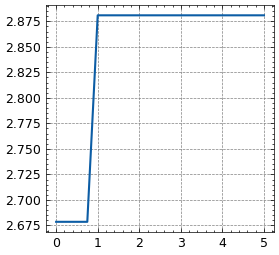

In [125]:
%matplotlib inline
plt.plot(data_cap.t_in[0,:], data_cap.x[0,0,:])
plt.show()
plt.close()

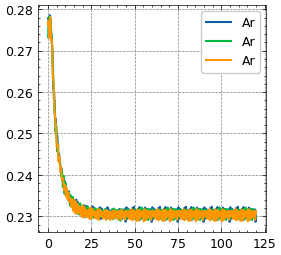

In [126]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,5):
    if i %2==0:
        plt.plot(data_cap.t_out[i, :], data_cap.y[i, 0, ...], label="Ar")
plt.legend()
plt.show()
plt.close()

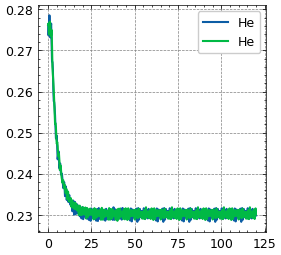

In [127]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,5):
    if not i %2==0:
        plt.plot(data_cap.t_out[i, :], data_cap.y[i, 0, ...], label="He")
plt.legend()
plt.show()
plt.close()

## reactor inlet

In [128]:
data_reac_inlet.setup("fit")
data_reac_inlet.x[0]

tensor([[0.4854, 0.4854, 0.4854, 0.4854, 0.4652, 0.4652, 0.4652, 0.4652, 0.4652,
         0.4652, 0.4652, 0.4652, 0.4652, 0.4652, 0.4652, 0.4652, 0.4652, 0.4652,
         0.4652, 0.4652, 0.4652]])

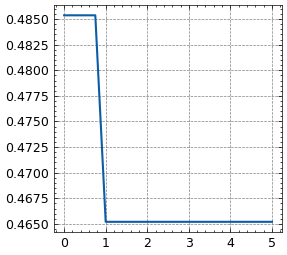

In [129]:
%matplotlib inline
plt.plot(data_reac_inlet.t_in[0,:], data_reac_inlet.x[0,0,:]) # switch delay hochsetzen
plt.show()
plt.close()

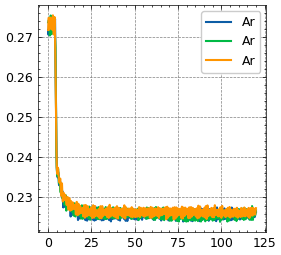

In [130]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,5):
    if i %2==0:
        plt.plot(data_reac_inlet.t_out[i, :], data_reac_inlet.y[i, 0, ...], label="Ar")
plt.legend()
plt.show()
plt.close()

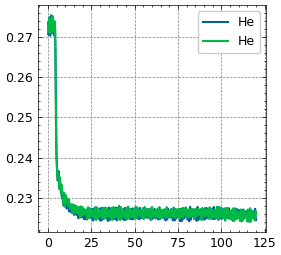

In [131]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,5):
    if not i %2==0:
        plt.plot(data_reac_inlet.t_out[i, :], data_reac_inlet.y[i, 0, ...], label="He")
plt.legend()
plt.show()
plt.close()

## reactor outlet

In [132]:
data_reac_outlet.setup("fit")
data_reac_outlet.x[0]

tensor([[0.2592, 0.2592, 0.2592, 0.2592, 0.2430, 0.2430, 0.2430, 0.2430, 0.2430,
         0.2430, 0.2430, 0.2430, 0.2430, 0.2430, 0.2430, 0.2430, 0.2430, 0.2430,
         0.2430, 0.2430, 0.2430]])

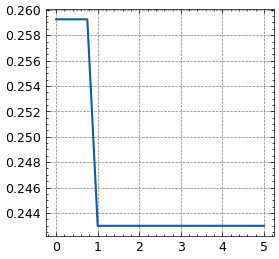

In [133]:
%matplotlib inline
plt.plot(data_reac_outlet.t_in[0,:], data_reac_outlet.x[0,0,:])
plt.show()
plt.close()

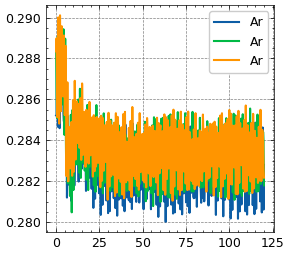

In [134]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,5):
    if i %2==0:
        plt.plot(data_reac_outlet.t_out[i, :], data_reac_outlet.y[i, 0, ...], label="Ar")
plt.legend()
plt.show()
plt.close()

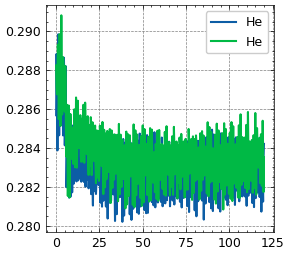

In [135]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,5):
    if not i %2==0:
        plt.plot(data_reac_outlet.t_out[i, :], data_reac_outlet.y[i, 0, ...], label="He")
plt.legend()
plt.show()
plt.close()

## total system

In [136]:
data_total_system.setup("fit")
data_total_system.x[0]

tensor([[0.2566, 0.2566, 0.2566, 0.2566, 0.2414, 0.2414, 0.2414, 0.2414, 0.2414,
         0.2414, 0.2414, 0.2414, 0.2414, 0.2414, 0.2414, 0.2414, 0.2414, 0.2414,
         0.2414, 0.2414, 0.2414]])

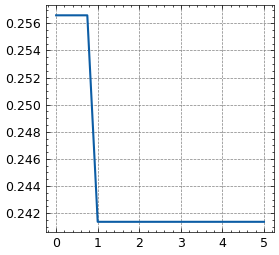

In [137]:
%matplotlib inline
plt.plot(data_total_system.t_in[0,:], data_total_system.x[0,0,:])
plt.show()
plt.close()

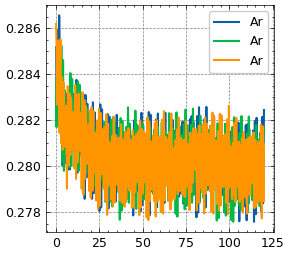

In [138]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,5):
    if i %2==0:
        plt.plot(data_total_system.t_out[i, :], data_total_system.y[i, 0, ...], label="Ar")
plt.legend()
plt.show()
plt.close()

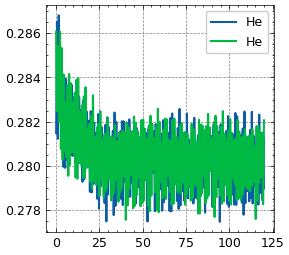

In [139]:
# plot t_in über x
%matplotlib inline
plt.figure()

for i in np.arange(0,5):
    if not i %2==0:
        plt.plot(data_total_system.t_out[i, :], data_total_system.y[i, 0, ...], label="He")
plt.legend()
plt.show()
plt.close()

# 7 - model setup & trainier initialization

In [140]:
model = RTDModule(
    kernel_sizes=n_kernels,
    kernel_times=t_kernels,
    learning_rate=4e-3,
    use_scheduler=False,
    scheduler_kwargs={"factor": 0.6, "patience": 2000},
)

my_logger = WandbLogger(log_model=True)
lr_callback = LearningRateMonitor()

max_epochs = 1_000

trainer = pl.Trainer(
    accelerator="cpu",
    max_epochs=max_epochs,
    enable_progress_bar=True,
    logger=my_logger,
    callbacks=[lr_callback],
)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


# 8 - Training

In [141]:
for conv_layer in model.net.conv_layers:
    conv_layer.set_to_direct_response()
    conv_layer.freeze()

In [142]:
model.net.conv_layers[3].unfreeze()
trainer.fit(model, data_cap)

log_plots(
    data_module=data_cap,
    model=model,
    index=0,
    Es_to_plot=[3],
)


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net  │ RTDNet │    464 │ train │     0 │
└───┴──────┴────────┴────────┴───────┴───────┘

Trainable params: 121                                                                                              
Non-trainable params: 343                                                                                          
Total params: 464                                                                                                  
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=1000` reached.


In [143]:
model.net.conv_layers[3].freeze()
model.net.conv_layers[0].unfreeze()
model.configure_optimizers()
trainer = pl.Trainer(
    accelerator="cpu",
    max_epochs=max_epochs,
    enable_progress_bar=True,
    logger=my_logger,
    callbacks=[lr_callback],
)
trainer.fit(model, data_reac_inlet)

log_plots(
    data_module=data_reac_inlet,
    model=model,
    index=0,
    Es_to_plot=[0, 3],
)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
C:\Users\admin\AppData\Roaming\Python\Python313\site-packages\lightning\pytorch\callbacks\model_checkpoint.py:881: UserWarning:

Checkpoint directory .\lightning_logs\6106apq2\checkpoints exists and is not empty.



┏━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net  │ RTDNet │    464 │ train │     0 │
└───┴──────┴────────┴────────┴───────┴───────┘

Trainable params: 81                                                                                               
Non-trainable params: 383                                                                                          
Total params: 464                                                                                                  
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=1000` reached.


In [144]:
model.net.conv_layers[0].freeze()
model.net.conv_layers[1].unfreeze()
model.configure_optimizers()
trainer = pl.Trainer(
    accelerator="cpu",
    max_epochs=max_epochs,
    enable_progress_bar=True,
    logger=my_logger,
    callbacks=[lr_callback],
)
trainer.fit(model, data_reac_outlet)

log_plots(
    data_module=data_reac_outlet,
    model=model,
    index=0,
    Es_to_plot=[0, 1, 3],
)

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net  │ RTDNet │    464 │ train │     0 │
└───┴──────┴────────┴────────┴───────┴───────┘

Trainable params: 181                                                                                              
Non-trainable params: 283                                                                                          
Total params: 464                                                                                                  
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=1000` reached.


In [145]:
model.net.conv_layers[1].freeze()
model.net.conv_layers[2].unfreeze()
model.configure_optimizers()
trainer = pl.Trainer(
    accelerator="cpu",
    max_epochs=max_epochs,
    enable_progress_bar=True,
    logger=my_logger,
    callbacks=[lr_callback],
)
trainer.fit(model, data_total_system)

log_plots(
    data_module=data_total_system,
    model=model,
    index=0,
    Es_to_plot=[0, 1, 2, 3],
)

plt.show()

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.


┏━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name ┃ Type   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ net  │ RTDNet │    464 │ train │     0 │
└───┴──────┴────────┴────────┴───────┴───────┘

Trainable params: 81                                                                                               
Non-trainable params: 383                                                                                          
Total params: 464                                                                                                  
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 10                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

`Trainer.fit` stopped: `max_epochs=1000` reached.


# 9 - Teilplots

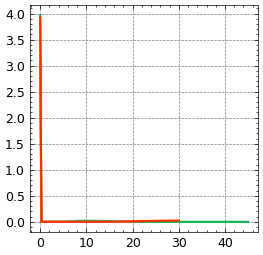

In [146]:
Es = []
ts = []
delta_ts = []

for i in np.arange(0,4):#
    Es.append(model.net.E[i].detach().numpy())
    ts.append(model.net.conv_layers[i].t_kernel.detach().numpy())
    delta_ts.append(delta_ts.append(model.net.delta_t[i].item()))
    plt.plot(ts[i], Es[i])

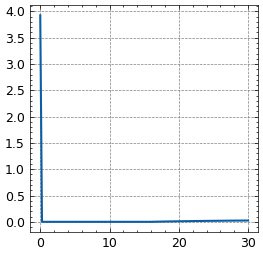

In [147]:
# capillary
plt.plot(ts[3], Es[3])

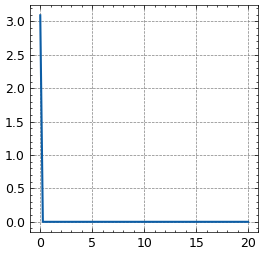

In [148]:
# reactor inlet
plt.plot(ts[0], Es[0])

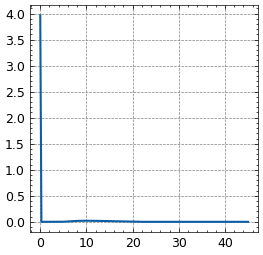

In [149]:
# reactor outlet
plt.plot(ts[1], Es[1])

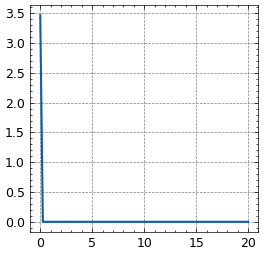

In [150]:
# gesamt system
plt.plot(ts[2], Es[2])

In [151]:
from datetime import datetime
d=datetime.now().strftime("%Y-%m-%d_%H%M%S")

data ={'ts':ts,
        'Es':Es,
        'delta_ts':delta_ts,

        't_in cap':data_cap.t_in.detach().numpy(),
        'x_in cap':data_cap.x.detach().numpy(),
        't_out cap':data_cap.t_out.detach().numpy(),
        'x_out cap':data_cap.y.detach().numpy(),

        't_in inlet':data_reac_inlet.t_in.detach().numpy(),
        'x_in inlet':data_reac_inlet.x.detach().numpy(),
        't_out inlet':data_reac_inlet.t_out.detach().numpy(),
        'x_out inlet':data_reac_inlet.y.detach().numpy(),

        't_in outlet':data_reac_inlet.t_in.detach().numpy(),
        'x_in outlet':data_reac_inlet.x.detach().numpy(),
        't_out outlet':data_reac_inlet.t_out.detach().numpy(),
        'x_out outlet':data_reac_inlet.y.detach().numpy(),

        't_in total':data_total_system.t_in.detach().numpy(),
        'x_in total':data_total_system.x.detach().numpy(),
        't_out total':data_total_system.t_out.detach().numpy(),
        'x_out total':data_total_system.y.detach().numpy(),}

np.save(f"Runs\Run_{d}.npy", data)

<>:28: SyntaxWarning:

invalid escape sequence '\R'

<>:28: SyntaxWarning:

invalid escape sequence '\R'

C:\Users\admin\AppData\Local\Temp\ipykernel_16356\440394437.py:28: SyntaxWarning:

invalid escape sequence '\R'

